# Системы линейных уравнений / 线性方程组

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.figsize": (8, 4.5),
    "figure.dpi": 110,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.prop_cycle": plt.cycler(color=["#356AE6", "#E07A25", "#2B8A6E", "#A64B78"]),
})

## 1. Запись системы / 方程组表示
$$\begin{cases}2x_1+x_2=5,\\x_1+3x_2=6.\end{cases}$$
Запишем систему в виде $A\mathbf{x}=\mathbf{b}$ и решим её через `np.linalg.solve`.

将方程组写成 $A\mathbf{x}=\mathbf{b}$，用 `np.linalg.solve` 求解。

In [2]:
A = np.array([[2., 1.],
              [1., 3.]])
b = np.array([5., 6.])
linear_solution = np.linalg.solve(A, b)
print("Решение / 解:", linear_solution)

Решение / 解: [1.8 1.4]


## 2. Проверка решения / 检查解
Подставим найденный вектор в исходную систему. Вектор `A @ x - b` называется невязкой.

把求得的向量代回原方程组。`A @ x - b` 称为残差向量。

In [3]:
linear_residual = A @ linear_solution - b
print("A @ x:", A @ linear_solution)
print("b:", b)
print("Невязка / 残差:", linear_residual)
print("Норма / 范数:", np.linalg.norm(linear_residual))

A @ x: [5. 6.]
b: [5. 6.]
Невязка / 残差: [0. 0.]
Норма / 范数: 0.0


## 3. Геометрический смысл / 几何意义
Каждое уравнение задаёт прямую. Их точка пересечения — решение системы.

每个方程表示一条直线，两条直线的交点就是方程组的解。

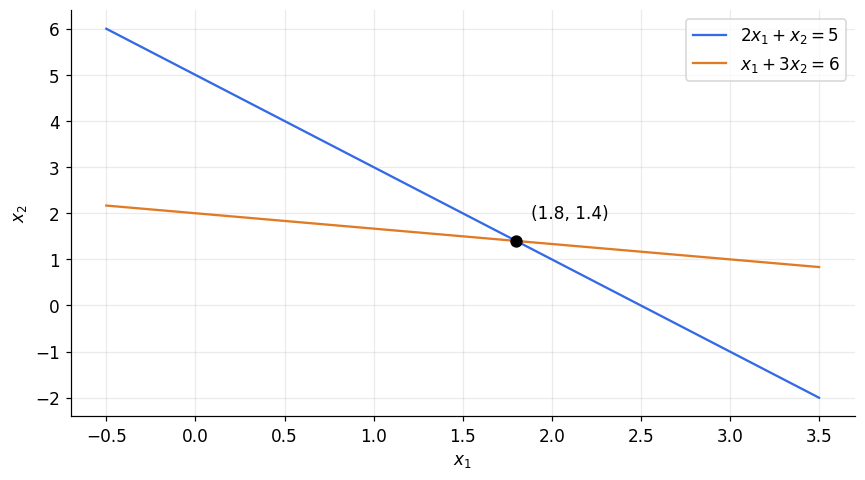

In [4]:
x1 = np.linspace(-0.5, 3.5, 250)
fig, ax = plt.subplots()
ax.plot(x1, (b[0] - A[0, 0]*x1) / A[0, 1], label=r"$2x_1+x_2=5$")
ax.plot(x1, (b[1] - A[1, 0]*x1) / A[1, 1], label=r"$x_1+3x_2=6$")
ax.scatter(*linear_solution, color="black", s=50, zorder=3)
ax.annotate("(1.8, 1.4)", linear_solution, xytext=(10, 15), textcoords="offset points")
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$")
ax.legend()
fig.tight_layout()
plt.show()

## 4. Один шаг метода Гаусса / 高斯消元的一步
Исключим первую неизвестную из второй строки расширенной матрицы, затем выполним обратную подстановку. Это пример для данной системы, а не универсальная реализация с выбором главного элемента.

从增广矩阵第二行中消去第一个未知数，再回代。这里只演示本题的步骤，不是带主元选择的通用实现。

In [5]:
augmented = np.column_stack((A, b)).copy()
print("До / 消元前:")
print(augmented)
factor = augmented[1, 0] / augmented[0, 0]
augmented[1] -= factor * augmented[0]
print("После / 消元后:")
print(augmented)
x2_gauss = augmented[1, 2] / augmented[1, 1]
x1_gauss = (augmented[0, 2] - augmented[0, 1]*x2_gauss) / augmented[0, 0]
gauss_solution = np.array([x1_gauss, x2_gauss])
print("Обратная подстановка / 回代:", gauss_solution)

До / 消元前:
[[2. 1. 5.]
 [1. 3. 6.]]
После / 消元后:
[[2.  1.  5. ]
 [0.  2.5 3.5]]
Обратная подстановка / 回代: [1.8 1.4]


## 5. Изменение правой части / 改变右端项
Сохраним матрицу `A`, но увеличим первый элемент `b` с 5 до 6. Первая прямая сдвинется, и точка пересечения изменится.

保持矩阵 `A` 不变，将 `b` 的第一个分量从 5 改为 6。第一条直线平移，交点随之改变。

Исходное / 原解: [1.8 1.4]
Новое / 新解: [2.4 1.2]
Изменение / 解的变化: [ 0.6 -0.2]


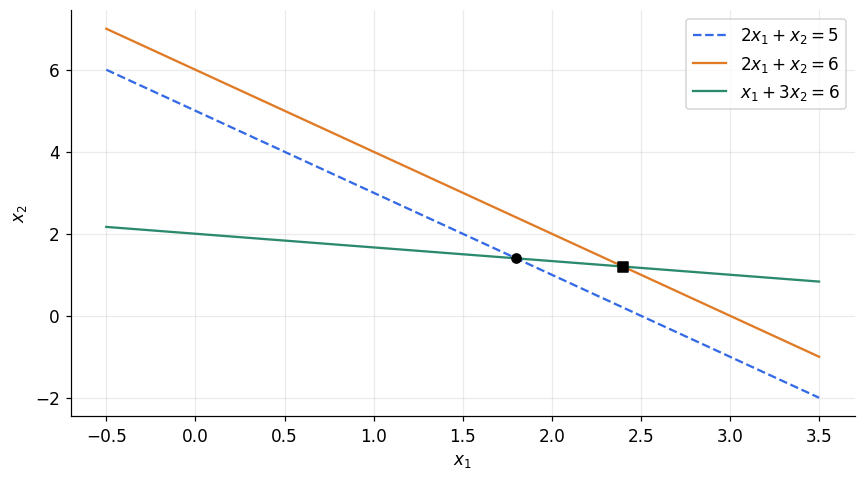

In [6]:
b_changed = np.array([6., 6.])
changed_solution = np.linalg.solve(A, b_changed)
print("Исходное / 原解:", linear_solution)
print("Новое / 新解:", changed_solution)
print("Изменение / 解的变化:", changed_solution - linear_solution)

fig, ax = plt.subplots()
ax.plot(x1, 5 - 2*x1, "--", label=r"$2x_1+x_2=5$")
ax.plot(x1, 6 - 2*x1, label=r"$2x_1+x_2=6$")
ax.plot(x1, (6 - x1)/3, label=r"$x_1+3x_2=6$")
ax.scatter(*linear_solution, color="black", zorder=3)
ax.scatter(*changed_solution, color="black", marker="s", zorder=3)
ax.set(xlabel=r"$x_1$", ylabel=r"$x_2$")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Почти параллельные прямые / 几乎平行的直线
Если уравнения почти зависимы, небольшое изменение данных может заметно изменить решение. Число обусловленности `cond(A)` характеризует чувствительность системы; малая невязка сама по себе не означает низкую чувствительность.

方程接近线性相关时，数据的微小变化可能导致解明显变化。条件数 `cond(A)` 描述系统的敏感程度；残差很小并不表示系统对数据扰动不敏感。

In [7]:
A_sensitive = np.array([[1., 1.], [1., 1. + 1e-6]])
b_sensitive = A_sensitive @ np.array([1., 1.])
x_sensitive = np.linalg.solve(A_sensitive, b_sensitive)
b_perturbed = b_sensitive + np.array([0., 1e-6])
x_perturbed = np.linalg.solve(A_sensitive, b_perturbed)
print("cond(A):", np.linalg.cond(A))
print("cond(A_sensitive):", np.linalg.cond(A_sensitive))
print("Изменение b / 右端项变化:", b_perturbed - b_sensitive)
print("До / 原解:", x_sensitive)
print("После / 扰动后的解:", x_perturbed)
print("Новая невязка / 新系统的残差:", A_sensitive @ x_perturbed - b_perturbed)

cond(A): 2.6180339887498953
cond(A_sensitive): 4000002.0005977233
Изменение b / 右端项变化: [0.e+00 1.e-06]
До / 原解: [1. 1.]
После / 扰动后的解: [-4.4408921e-10  2.0000000e+00]
Новая невязка / 新系统的残差: [0. 0.]


## 7. Вырожденная система / 奇异方程组
В этой системе второе уравнение — удвоенное первое. Единственного решения нет; `solve` сообщает об ошибке.

本例第二个方程是第一个的两倍，没有唯一解，`solve` 会报错。

In [8]:
A_singular = np.array([[1., 2.], [2., 4.]])
b_singular = np.array([3., 6.])
try:
    np.linalg.solve(A_singular, b_singular)
except np.linalg.LinAlgError as error:
    print("Единственного решения нет / 无唯一解:", error)

Единственного решения нет / 无唯一解: Singular matrix
